In [1]:
import random
from pathlib import Path

import implicit
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import surprise
from scipy.sparse import csr_matrix

from tarea_01.utils import calculate_metrics


# Cargar dataset

In [2]:
dataset_path = Path('../dataset')
train_df = pd.read_csv(dataset_path / 'train.csv')
test_df = pd.read_csv(dataset_path / 'validation.csv')

reader = surprise.Reader(rating_scale=(0, 5))

# 1. Dataset y trainset completo para entrenar
train_data = surprise.Dataset.load_from_df(
    train_df[["user_id", "recipe_id", "rating"]], reader=reader
)
trainset = train_data.build_full_trainset()

# 2. Testset exclusivamente para RMSE (sin negativos)
testset_rating = list(test_df[["user_id", "recipe_id", "rating"]].itertuples(index=False, name=None))

# 3. Testset para Ranking (con negativos muestreados)
def build_ranking_testset(train_df, test_df, n_negatives=100, seed=42):
    rng = random.Random(seed)
    all_items = set(train_df["recipe_id"].unique())
    user_seen_train = train_df.groupby("user_id")["recipe_id"].apply(set).to_dict()
    user_seen_test = test_df.groupby("user_id")["recipe_id"].apply(set).to_dict()

    evaluation_testset = []

    # Positivos reales
    for row in test_df.itertuples(index=False):
        evaluation_testset.append((row.user_id, row.recipe_id, float(row.rating)))

    # Negativos no interactuados
    for uid, test_items in user_seen_test.items():
        seen = user_seen_train.get(uid, set()) | test_items
        unseen = list(all_items - seen)

        neg_samples = rng.sample(unseen, min(len(unseen), n_negatives))
        for iid in neg_samples:
            evaluation_testset.append((uid, iid, 0.0))

    return evaluation_testset

testset_ranking = build_ranking_testset(train_df, test_df, n_negatives=100)

# Definir modelos baseline

In [3]:
from surprise import AlgoBase, PredictionImpossible


class BestRated(AlgoBase):

    def __init__(self):
        AlgoBase.__init__(self)

    def fit(self, trainset):
        AlgoBase.fit(self, trainset)
        self.item_means = {}
        for i, ratings in trainset.ir.items():
            self.item_means[i] = sum(r for _, r in ratings) / len(ratings)
        return self

    def estimate(self, u, i):
        if not self.trainset.knows_item(i):
            raise PredictionImpossible("Item is unknown.")
        return self.item_means[i]


class MostPopular(AlgoBase):

    def __init__(self):
        super().__init__()

    def fit(self, trainset):
        super().fit(trainset)
        self.item_counts = {i: len(ratings) for i, ratings in trainset.ir.items()}
        self.max_count = max(self.item_counts.values()) if self.item_counts else 1.0
        return self

    def estimate(self, u, i):
        if not self.trainset.knows_item(i):
            raise PredictionImpossible("Item is unknown.")

        low, high = self.trainset.rating_scale
        norm_pop = self.item_counts[i] / self.max_count
        return low + norm_pop * (high - low)

class UniformRandom(AlgoBase):

    def __init__(self, random_state=None):
        super().__init__()
        self.rng = np.random.default_rng(random_state)

    def fit(self, trainset):
        super().fit(trainset)
        return self

    def estimate(self, u, i):
        low, high = self.trainset.rating_scale
        return self.rng.uniform(low, high)


# Ejecucion de modelos

In [4]:
metrics = {}

In [5]:
model = surprise.BaselineOnly()
model.fit(trainset)

metrics['ALS'] = calculate_metrics(
    model=model,
    testset_rating=testset_rating,
    testset_ranking=testset_ranking,
    k=10,
    threshold=4.0,
)

model = BestRated()
model.fit(trainset)

metrics['BestRated'] = calculate_metrics(
    model=model,
    testset_rating=testset_rating,
    testset_ranking=testset_ranking,
    k=10,
    threshold=4.0,
)


model = MostPopular()
model.fit(trainset)

metrics['MostPopular'] = calculate_metrics(
    model=model,
    testset_rating=testset_rating,
    testset_ranking=testset_ranking,
    k=10,
    threshold=4.0,
)

model = UniformRandom()
model.fit(trainset)

metrics['Random'] = calculate_metrics(
    model=model,
    testset_rating=testset_rating,
    testset_ranking=testset_ranking,
    k=10,
    threshold=4.0,
)

Estimating biases using als...


In [6]:
params = {
    "k": [20, 30, 40, 50, 60, 70, 80],
    "sim_options": {
        "name": ["pearson", "msd"],
        "user_based": [True],
    },
}

model = surprise.model_selection.GridSearchCV(
    surprise.KNNBasic,
    params,
    measures=["rmse", "mae"],
    cv=3,
    n_jobs=-1,
)

model.fit(train_data)
best_model = model.best_estimator["rmse"]
best_model.fit(trainset)

metrics['Knn user'] = calculate_metrics(
    model=best_model,
    testset_rating=testset_rating,
    testset_ranking=testset_ranking,
    k=10,
    threshold=4.0,
)

Computing the msd similarity matrix...
Done computing similarity matrix.


In [7]:
params = {
    "k": [20, 30, 40, 50, 60, 70, 80],
    "sim_options": {
        "name": ["pearson", "msd"],
        "user_based": [False],
    },
}

model = surprise.model_selection.GridSearchCV(
    surprise.KNNBasic,
    params,
    measures=["rmse", "mae"],
    cv=3,
    n_jobs=-1,
)

model.fit(train_data)
best_model = model.best_estimator["rmse"]
best_model.fit(trainset)

metrics['Knn item'] = calculate_metrics(
    model=best_model,
    testset_rating=testset_rating,
    testset_ranking=testset_ranking,
    k=10,
    threshold=4.0,
)

Computing the msd similarity matrix...
Done computing similarity matrix.


In [8]:
params = {"n_epochs": [5, 10], "lr_all": [0.002, 0.005], "reg_all": [0.4, 0.6]}
model = surprise.model_selection.GridSearchCV(surprise.SVD, params, measures=["rmse", "mae"], cv=3)

model.fit(train_data)
best_model = model.best_estimator["rmse"]
best_model.fit(trainset)

metrics['Svd'] = calculate_metrics(
    model=best_model,
    testset_rating=testset_rating,
    testset_ranking=testset_ranking,
    k=10,
    threshold=4.0,
)

In [9]:
class ImplicitWrapper(AlgoBase):
    """
    Wrapper que adapta cualquier modelo de la librería 'implicit' 
    para ser utilizado como un modelo nativo de Surprise.
    """
    def __init__(self, implicit_model, binarize_threshold=None):
        super().__init__()
        self.implicit_model = implicit_model
        self.binarize_threshold = binarize_threshold

    def fit(self, trainset):
        super().fit(trainset)

        rows, cols, data = [], [], []
        for inner_u, user_ratings in trainset.ur.items():
            for inner_i, rating in user_ratings:
                # Opcional: binarizar calificaciones para modelos de ranking implícito
                if self.binarize_threshold is not None:
                    val = 1.0 if rating >= self.binarize_threshold else 0.0
                else:
                    val = float(rating)

                if val > 0:
                    rows.append(inner_u)
                    cols.append(inner_i)
                    data.append(val)

        # Crear matriz dispersa User-Item con forma (n_users, n_items)
        user_item_matrix = csr_matrix(
            (data, (rows, cols)),
            shape=(trainset.n_users, trainset.n_items),
            dtype=np.float32,
        )

        # Entrenar el modelo de 'implicit'
        self.implicit_model.fit(user_item_matrix)
        return self

    def estimate(self, u, i):
        # 'u' e 'i' recibidos por estimate() ya son índices internos (inner IDs)
        if not (self.trainset.knows_user(u) and self.trainset.knows_item(i)):
            raise PredictionImpossible("Usuario o ítem desconocido para el modelo implícito.")

        # Obtener los vectores de factores latentes aprendidos
        user_factor = self.implicit_model.user_factors[u]
        item_factor = self.implicit_model.item_factors[i]

        # El score predicho para ordenar rankings es el producto punto
        return float(np.dot(user_factor, item_factor))

In [10]:
bpr_native = implicit.bpr.BayesianPersonalizedRanking(
    factors=30,
    learning_rate=0.05,
    regularization=0.01,
    iterations=50,
    random_state=42,
)

model_bpr = ImplicitWrapper(bpr_native, binarize_threshold=4.0)
model_bpr.fit(trainset)

# 3. Evaluar con calculate_metrics
metrics["BPR"] = calculate_metrics(
    model=model_bpr,
    testset_rating=testset_rating,
    testset_ranking=testset_ranking,
    k=10,
    threshold=4.0,
)

  0%|          | 0/50 [00:00<?, ?it/s]

In [11]:
df = pd.DataFrame(metrics).T
df

,RMSE,MAE,Recall@10,Precision@10,NDCG@10,MAP@10,Diversity,Novelty
ALS,0.8818,0.4857,0.1435,0.0836,0.1407,0.0829,0.9835,12.8193
BestRated,0.9210,0.5255,0.0622,0.0393,0.0841,0.0514,0.9818,13.4591
MostPopular,4.3004,4.1823,0.3603,0.1716,0.3188,0.2048,0.9566,11.0394
Random,2.7312,2.3266,0.0944,0.0514,0.0770,0.0356,0.9855,13.0772
Knn user,0.9367,0.5067,0.1556,0.0683,0.2204,0.1628,0.9863,13.4684
Knn item,0.9108,0.4852,0.2334,0.0938,0.2722,0.2273,0.9866,13.3765
Svd,0.8814,0.4958,0.1053,0.0610,0.0957,0.0478,0.9838,12.9577
BPR,3.8874,3.6834,0.2273,0.1113,0.1854,0.1019,0.9786,12.7980


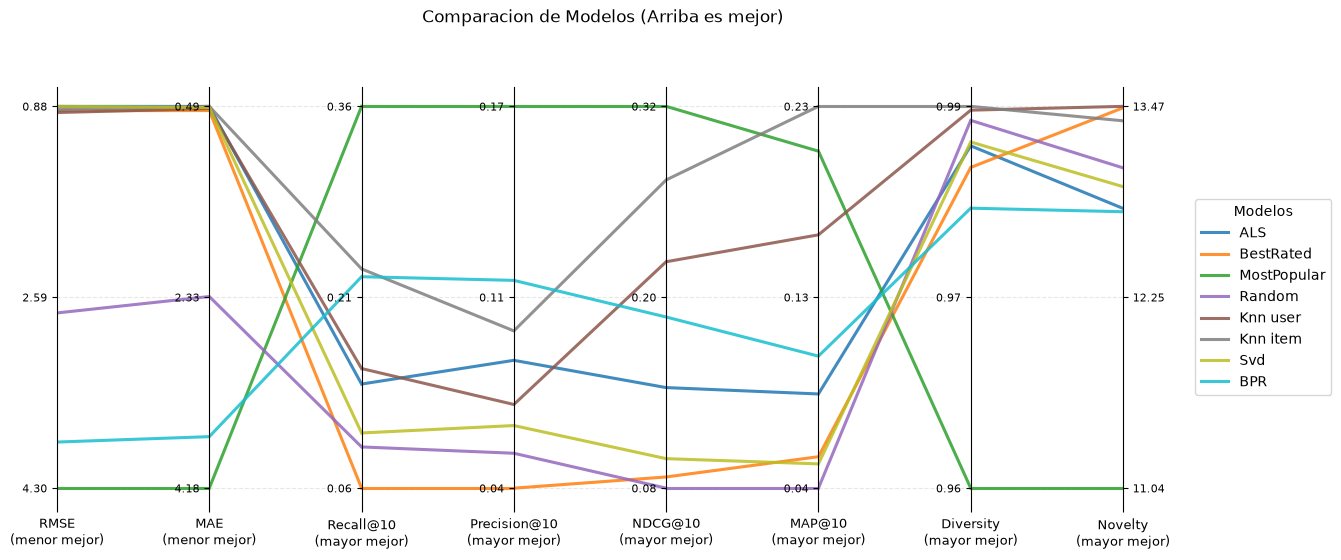

In [14]:
columns = df.columns.tolist()

df_norm = pd.DataFrame(index=df.index)
for col in columns:
    c_min, c_max = df[col].min(), df[col].max()
    if col in ["RMSE", "MAE"]:
        df_norm[col] = (c_max - df[col]) / (c_max - c_min)
    else:
        df_norm[col] = (df[col] - c_min) / (c_max - c_min)

fig, axes = plt.subplots(
    1, len(columns) - 1, sharey=False, figsize=(13, 6),
    gridspec_kw={'wspace': 0}
)

colors = plt.cm.tab10(np.linspace(0, 1, len(df)))

for idx, (model_name, row) in enumerate(df_norm.iterrows()):
    y_vals = row.values
    for i in range(len(columns) - 1):
        axes[i].plot(
            [i, i + 1],
            [y_vals[i], y_vals[i + 1]],
            color=colors[idx],
            linewidth=2.2,
            alpha=0.85,
            label=model_name if i == 0 else ""
        )

for i, ax in enumerate(axes):
    col = columns[i]
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlim(i, i + 1)

    ax.spines['left'].set_position(('data', i))
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)

    real_min, real_max = df[col].min(), df[col].max()
    if col in ["RMSE", "MAE"]:
        ticks_labels = [f"{real_max:.2f}", f"{(real_min+real_max)/2:.2f}", f"{real_min:.2f}"]
    else:
        ticks_labels = [f"{real_min:.2f}", f"{(real_min+real_max)/2:.2f}", f"{real_max:.2f}"]

    ax.set_yticks([0.0, 0.5, 1.0])
    ax.set_yticklabels(ticks_labels, fontsize=8)
    ax.set_xticks([i])
    label_name = f"{col}\n(menor mejor)" if col in ["RMSE", "MAE"] else f"{col}\n(mayor mejor)"
    ax.set_xticklabels([label_name], fontsize=9)
    ax.grid(axis='y', linestyle='--', alpha=0.3)

last_ax = axes[-1]
last_col = columns[-1]
last_min, last_max = df[last_col].min(), df[last_col].max()
ax_right = last_ax.twinx()
ax_right.set_ylim(-0.05, 1.05)
ax_right.spines['left'].set_visible(False)
ax_right.spines['top'].set_visible(False)
ax_right.spines['bottom'].set_visible(False)
ax_right.set_yticks([0.0, 0.5, 1.0])
ax_right.set_yticklabels([f"{last_min:.2f}", f"{(last_min+last_max)/2:.2f}", f"{last_max:.2f}"], fontsize=8)

last_ax.set_xticks([len(columns) - 2, len(columns) - 1])
last_ax.set_xticklabels([f"{columns[-2]}\n(mayor mejor)", f"{last_col}\n(mayor mejor)"], fontsize=9)

fig.suptitle("Comparacion de Modelos (Arriba es mejor)", fontsize=12, y=0.98)
fig.legend(loc='center left', bbox_to_anchor=(0.95, 0.5), title="Modelos", frameon=True)
plt.subplots_adjust(left=0.08, right=0.90, top=0.85, bottom=0.15)
plt.show()